# AAI-521 Applied Computer Vision for AI
## Final Project: Old Photo Restoration Studio
### Stage 1: Data Ingestion and Image Preprocessing Pipeline

**Student Name:** N L N Sai Krishna Akula  
**Course:** AAI-521: Applied Computer Vision for AI  
**Degree Program:** Master of Science in Applied Artificial Intelligence (MS-AAI)  
**University:** University of San Diego, Shiley-Marcos School of Engineering  
**Instructor:** Rajesh Soni, M.S.  

---

### Stage 1 Overview & Objectives
Stage 1 serves as the foundational data gateway and preprocessing engine for the Old Photo Restoration Studio. In real-world archival photo restoration, historical images arrive in diverse and unpredictable formats: arbitrary resolutions (from small portrait cards to massive 4K film scans), inconsistent EXIF orientation metadata, mixed color channels (grayscale prints, 4-channel CMYK prepress scans, transparent RGBA uploads), and physical surface damage (scratches, creases, dust, tears, and sepia fading).

The objective of Stage 1 is to transform these raw historical assets into clean, standardized, high-performance PyTorch tensors, while generating deterministic paired training datasets for downstream deep learning models.

#### Key Engineering Components in Stage 1:
1. **Dataset Ingestion & Topology:** Programmatically downloads and organizes benchmark datasets into `data/raw/`:
   - **ARTeFACT Dataset:** 418 real historical documents and photographs with pixel-level ground-truth damage masks.
   - **OpenPhoto Restore Dataset:** Paired high-resolution clean and damaged historical photographs.
   - **4K Film Scans Benchmark (DOI: 10.6084/m9.figshare.21803304):** 88 full-resolution 3K/4K scans (44 damaged + 44 restored, 417 MB) for tile-based stress testing and holdout evaluation.
   - **humanface8000 Dataset:** 8,164 paired color and grayscale portraits from Kaggle for face repair (Stage 3) and enhancement (Stage 5).
2. **Format Extraction & Standardization (Parquet to Clean PNGs):** Extracts embedded binary streams from Hugging Face Apache Parquet tables directly into standardized 3-channel 8-bit sRGB PNG images and single-channel binary masks ($0 = \text{clean background}$, $255 = \text{damage}$) saved in `data/cleaned/`. Corrects EXIF orientation tags and normalizes color spaces.
3. **Spatial Stride Alignment via Reflection Padding:** Analyzes standard padding strategies (Zero, Replication, Circular, Reflection) and implements reflection padding to pad arbitrary dimensions to exact multiples of 32 (required by multi-stage downsampling networks like U-Net) without introducing artificial boundary step-edges.
4. **High-Resolution Image Tiling:** Resolves GPU VRAM limitations on large scans (e.g., $4000 \times 3000$) through a step-by-step tiling walkthrough using overlapping $512 \times 512$ patches (64-pixel stride overlap) and seamlessly reconstructing the full image using 2D cosine (Hann) window feathering, achieving $\text{PSNR} > 40\text{ dB}$ with zero seam artifacts.
5. **Deterministic Synthetic Damage Generation:** Solves the scarcity of real damaged-clean pairs by procedurally generating physical photo defects on clean historical base photographs from OpenPhoto Restore:
   - Cubic Bézier curve scratches
   - Structural fold creases with shadow and highlight ridges
   - Airborne particulate dust and pepper specks
   - Corner paper tears
   - Non-linear sepia aging and Gaussian film grain
   - Synchronized ground-truth binary damage masks
   - Pre-generating and caching 800 training and 200 validation triplets to disk in `data/synthetic/` with a locked random seed (`seed=42`) for 100% reproducible experiments and maximum GPU throughput.
6. **High-Throughput PyTorch DataLoaders:** Production-grade `Dataset` and `DataLoader` abstractions with multi-worker support streaming directly from disk for downstream Stage 2 (Damage Detection) and Stage 3 (Physical Repair).
7. **End-to-End Pipeline Verification:** Validates numerical reconstruction precision, mask alignment, and tensor batch collation ($B, C, H, W$) with values normalized to $[0.0, 1.0]$.



In [1]:
# ==============================================================================
# Environment Setup: Automated Dependency Installation
# ==============================================================================
# Installs all required libraries for the data processing pipeline:
# - pyarrow: High-performance reading and deserialization of Apache Parquet tables.
# - huggingface_hub: Programmatic streaming and snapshot downloads of benchmark datasets.
# - pillow & opencv-python-headless: Comprehensive digital image processing and format conversion.
# - torchvision & torch: Tensor transformations, dataset interfaces, and GPU acceleration.
# - tqdm & matplotlib kagglehub: Interactive console progress tracking and diagnostic visual plots.
# ==============================================================================
!pip install -q pyarrow huggingface_hub pillow opencv-python-headless torchvision tqdm matplotlib kagglehub




[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ==============================================================================
# Core Library Imports & Deterministic Runtime Configuration
# ==============================================================================
import os

# ------------------------------------------------------------------------------
# Kaggle API Authentication Token
# ------------------------------------------------------------------------------
# Programmatic ingestion of Kaggle datasets (e.g., humanface8000) requires API authentication.
KAGGLE_API_TOKEN = "KGAT_5a546add8475ee37648b3856f42d8984"
os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

import io
import json
import math
import random
import shutil
import sys
import urllib.request
import zipfile
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF
from huggingface_hub import snapshot_download
from PIL import Image, ImageOps
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import kagglehub

# ------------------------------------------------------------------------------
# 1. Deterministic Random Number Generator (RNG) Seeding
# ------------------------------------------------------------------------------
# Archival restoration benchmarking requires complete experimental reproducibility.
# The random seed is fixed across Python, NumPy, PyTorch CPU, and PyTorch CUDA backends.
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# ------------------------------------------------------------------------------
# 2. Hardware Acceleration Diagnostics & Environment Verification
# ------------------------------------------------------------------------------
# Detects CUDA capability to inform downstream tiling and tensor processing.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[Device] Hardware Accelerator: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"[GPU] {torch.cuda.get_device_name(0)}")
    print(f"[VRAM Available] {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"[Auth] Kaggle API Token:      {KAGGLE_API_TOKEN[:12]}... (configured)")

# ------------------------------------------------------------------------------
# 3. Robust Repository Root and Directory Topology Resolution
# ------------------------------------------------------------------------------
def get_project_root() -> Path:
    """
    Dynamically resolves the absolute path to the repository root directory.
    
    Traverses upward from current working directory to identify the project root
    containing 'notebooks', 'data', and 'app' subdirectories, ensuring consistent
    path resolution regardless of whether execution occurs in IDE, terminal, or Jupyter.
    
    Returns:
        Path: Absolute path to the repository root.
    """
    current = Path.cwd().resolve()
    if (current / "notebooks").exists() and (current / "data").exists() and (current / "app").exists():
        return current
    for candidate in current.parents:
        if (candidate / "notebooks").exists() and (candidate / "data").exists() and (candidate / "app").exists():
            return candidate
    for child in [
        current / "Final Project" / "old-photo-restoration-studio",
        current / "old-photo-restoration-studio",
    ]:
        if child.exists() and (child / "notebooks").exists():
            return child
    return current


BASE_DIR = get_project_root()
DATA_DIR = BASE_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
CLEANED_DATA_DIR = DATA_DIR / "cleaned"
SYNTHETIC_DATA_DIR = DATA_DIR / "synthetic"
MODELS_DIR = BASE_DIR / "models"
RESULTS_DIR = BASE_DIR / "results"

# Ensure all directory structures exist on disk
for directory in [RAW_DATA_DIR, CLEANED_DATA_DIR, SYNTHETIC_DATA_DIR, MODELS_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

def format_display_path(path: Union[str, Path]) -> str:
    """Returns a clean path starting from the project directory name (old-photo-restoration-studio)."""
    p = Path(path)
    parts = p.parts
    if "old-photo-restoration-studio" in parts:
        idx = parts.index("old-photo-restoration-studio")
        return str(Path(*parts[idx:]))
    return str(p)


print(f"[Paths] Project Root:         {format_display_path(BASE_DIR)}")
print(f"[Paths] Data Directory:       {format_display_path(DATA_DIR)}")
print(f"[Paths] Clean Directory:      {format_display_path(CLEANED_DATA_DIR)}")


[Device] Hardware Accelerator: cpu
[Auth] Kaggle API Token:      KGAT_5a546ad... (configured)
[Paths] Project Root:         old-photo-restoration-studio
[Paths] Data Directory:       old-photo-restoration-studio\data
[Paths] Clean Directory:      old-photo-restoration-studio\data\cleaned


## 1. Dataset Ingestion

The restoration pipeline relies on benchmark datasets targeting specific stages of the architecture:

* **ARTeFACT** (Ivanova et al., WACV 2025): 418 real historical damaged prints with dense, pixel-level binary damage masks. Used for 5-fold cross-validation in **Stage 2 (Damage Detection)**.
* **OpenPhoto Restore** (Chin et al.): Paired clean and damaged historical photographs. Used as the pristine photographic base for synthetic degradation synthesis and for training the **Latent-Space Repair Model (Stage 3)**.
* **Real Damaged Film Scans** (Ivanova et al., 2023, DOI: 10.6084/m9.figshare.21803304): 88 full-resolution 3K/4K scans (44 authentically damaged film scans paired with 44 professional manual restorations, 417.30 MB total). Serves as the holdout benchmark for patch tiling stress-tests and final end-to-end evaluation.
* **humanface8000** (Adhikari, Kaggle): 8,164 paired color and grayscale facial portraits. Used for **Face Inpainting (Stage 3)** and **Facial Prior Enhancement (Stage 5)**.

Automated ingestion routines fetch the raw archives into `data/raw/`, keeping the source data intact before standardization.



In [3]:
# ==============================================================================
# Automated Dataset Ingestion Subsystem
# ==============================================================================

def download_artefact_dataset(target_dir: Path) -> Path:
    """
    Programmatically ingests the ARTeFACT dataset from Hugging Face.
    
    Checks for existing Parquet shards to avoid redundant bandwidth consumption.
    If fewer than 28 shards exist, triggers snapshot_download to fetch the raw table data.
    
    Args:
        target_dir (Path): Destination directory for raw ARTeFACT Parquet shards.
        
    Returns:
        Path: Verified path to the target directory containing shards.
    """
    target_dir.mkdir(parents=True, exist_ok=True)
    parquets = list(target_dir.rglob("*.parquet"))
    if len(parquets) >= 28:
        print(f"[Ingestion] ARTeFACT already downloaded: {len(parquets)} shards in {format_display_path(target_dir)}")
        return target_dir
    print("[Ingestion] Downloading ARTeFACT dataset from Hugging Face...")
    snapshot_download(
        repo_id="danielaivanova/damaged-media",
        repo_type="dataset",
        local_dir=str(target_dir),
        ignore_patterns=["*.git*"]
    )
    return target_dir


def download_openphoto_dataset(target_dir: Path) -> Path:
    """
    Programmatically ingests the OpenPhoto Restore dataset from Hugging Face.
    
    Verifies the presence of Parquet shards containing paired pristine and damaged
    photographs. Resumes incomplete downloads automatically.
    
    Args:
        target_dir (Path): Destination directory for raw OpenPhoto Parquet shards.
        
    Returns:
        Path: Verified path to the target directory containing shards.
    """
    target_dir.mkdir(parents=True, exist_ok=True)
    parquets = list(target_dir.rglob("*.parquet"))
    if len(parquets) >= 9:
        print(f"[Ingestion] OpenPhoto Restore already downloaded: {len(parquets)} shards in {format_display_path(target_dir)}")
        return target_dir
    print(f"[Ingestion] Downloading / resuming OpenPhoto Restore dataset ({len(parquets)} shards present)...")
    snapshot_download(
        repo_id="joshuachin/openphoto-restore-dataset",
        repo_type="dataset",
        local_dir=str(target_dir),
        ignore_patterns=["*.git*"]
    )
    return target_dir


def download_film_scans_dataset(target_dir: Path) -> Path:
    """
    Downloads the high-resolution 4K film scans benchmark from Figshare.
    
    Streams the archive file directly from the Figshare Version 2 endpoint:
    https://figshare.com/ndownloader/articles/21803304/versions/2
    and unpacks the contained photographic scans into data/raw/film_scans_4k/
    for tiling stress tests.
    
    Args:
        target_dir (Path): Destination directory (data/raw/film_scans_4k).
        
    Returns:
        Path: Verified directory containing downloaded film scans.
    """
    target_dir.mkdir(parents=True, exist_ok=True)
    existing_scans = list(target_dir.glob("*.jpg")) + list(target_dir.glob("*.png"))
    if len(existing_scans) >= 88:
        print(f"[Ingestion] Film scans already downloaded: {len(existing_scans)} scans (417.30 MB) in {format_display_path(target_dir)}")
        return target_dir

    archive_url = "https://figshare.com/ndownloader/articles/21803304/versions/2"
    archive_file = target_dir / "film_scans.zip"
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

    print(f"[Ingestion] Downloading film scans archive: {archive_url} -> {archive_file.name}...")
    try:
        req = urllib.request.Request(archive_url, headers=headers)
        with urllib.request.urlopen(req, timeout=60) as resp, open(archive_file, "wb") as out_f:
            shutil.copyfileobj(resp, out_f)

        print(f"[Ingestion] Extracting {archive_file.name}...")
        with zipfile.ZipFile(archive_file, "r") as zip_ref:
            zip_ref.extractall(target_dir)
        archive_file.unlink()
    except Exception as exc:
        print(f"[Ingestion Notice] Film scans download notice: {exc}")

    return target_dir


def download_humanface_dataset(target_dir: Path) -> Path:
    """
    Ingests humanface8000 paired portrait photographs from Kaggle into data/raw/humanface8000/.
    
    Verifies existing color and gray folders containing 8,164 pairs to avoid redundant downloads.
    Authenticates via kagglehub using configured API token.
    
    Args:
        target_dir (Path): Destination directory (data/raw/humanface8000).
        
    Returns:
        Path: Verified path to dataset root.
    """
    target_dir.mkdir(parents=True, exist_ok=True)
    color_dir = target_dir / "color"
    gray_dir = target_dir / "gray"
    
    if color_dir.exists() and gray_dir.exists() and len(list(color_dir.glob("*.jpg"))) >= 8000:
        count = len(list(color_dir.glob("*.jpg")))
        print(f"[Ingestion] humanface8000 already downloaded: {count} pairs in {format_display_path(target_dir)}")
        return target_dir

    print("[Ingestion] Downloading humanface8000 dataset from Kaggle via kagglehub...")
    os.environ["KAGGLE_API_TOKEN"] = "KGAT_5a546add8475ee37648b3856f42d8984"
    download_path = kagglehub.dataset_download("bharatadhikari/humanface8000")
    src_root = Path(download_path) / "landscape Images"
    if (src_root / "color").exists():
        shutil.move(str(src_root / "color"), str(color_dir))
    if (src_root / "gray").exists():
        shutil.move(str(src_root / "gray"), str(gray_dir))
    return target_dir


## 2. Image Standardization and Format Extraction

Raw historical datasets arrive in disparate container formats and encodings:
* Apache Parquet tables with embedded compressed binary streams (ARTeFACT, OpenPhoto Restore)
* Uncompressed portrait photograph archives (humanface8000)
* Ultra-high-resolution 3K/4K photographic film scans (Figshare 21803304)

The standardization engine normalizes all photographic assets into uniform, disk-cached assets in `data/cleaned/`:
1. **Photographic Prints & Masks (ARTeFACT):** 418 pairs of 3-channel sRGB PNGs and single-channel binary damage masks ($0 = \text{background}$, $255 = \text{damage}$).
2. **Historical Paired Prints (OpenPhoto Restore):** 1,000 paired clean and damaged photographic PNGs.
3. **Facial Portraits (humanface8000):** 1,000 paired $256 \times 256$ sRGB color ground truths and grayscale degraded observations.
4. **High-Resolution Film Scans (Real Damaged Film Scans):** 44 paired authentically damaged film scans and professional manual restorations with metadata audit manifest.

Standardized caching avoids repeated deserialization overhead, maximizing PyTorch DataLoader throughput.


In [4]:
# ==============================================================================
# Image Standardization & Parquet Format Extraction Subsystem
# ==============================================================================

def load_and_standardize_image(
    image_input: Union[str, Path, np.ndarray, Image.Image],
    target_size: Optional[Tuple[int, int]] = None,
    normalize_to_unit_range: bool = True
) -> np.ndarray:
    """
    Loads, sanitizes, and standardizes an input image to a 3-channel sRGB NumPy array.
    
    Pipeline operations:
    1. Ingestion: Reads file path, NumPy array, or PIL Image.
    2. EXIF Transposition: Bakes orientation tags directly into coordinates.
    3. Channel Harmonization: Converts CMYK, RGBA, and Grayscale to standard 3-channel sRGB.
    4. Optional Resampling: High-fidelity Lanczos down/up-scaling if target_size is set.
    5. Normalization: Scales pixel intensities from uint8 [0, 255] to float32 [0.0, 1.0].
    
    Args:
        image_input: File path, raw array, or PIL instance.
        target_size: Optional (width, height) tuple for spatial resizing.
        normalize_to_unit_range: If True, returns float32 in [0.0, 1.0]; else uint8 in [0, 255].
        
    Returns:
        np.ndarray: Standardized image array of shape (H, W, 3).
    """
    # Step 1: Input polymorphic parsing
    if isinstance(image_input, (str, Path)):
        img = Image.open(image_input)
    elif isinstance(image_input, np.ndarray):
        if image_input.ndim == 2:
            img = Image.fromarray(image_input, mode="L")
        elif image_input.ndim == 3 and image_input.shape[2] == 3:
            img = Image.fromarray(image_input, mode="RGB")
        elif image_input.ndim == 3 and image_input.shape[2] == 4:
            img = Image.fromarray(image_input, mode="RGBA")
        else:
            raise ValueError(f"Unsupported array shape for image standardization: {image_input.shape}")
    elif isinstance(image_input, Image.Image):
        img = image_input
    else:
        raise TypeError(f"Unsupported image type passed to standardizer: {type(image_input)}")

    # Step 2: EXIF Orientation Transpose
    # Corrects images shot on rotated physical film scanners or vintage cameras
    try:
        img = ImageOps.exif_transpose(img)
    except Exception:
        pass

    # Step 3: Color Space Normalization to Standard 3-channel sRGB
    if img.mode == "CMYK":
        # Archival book scans using subtractive pigments are converted to additive sRGB
        img = img.convert("RGB")
    elif img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info):
        # Flatten transparent alpha layers over a clean white canvas
        img = img.convert("RGBA")
        white_canvas = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(white_canvas, img).convert("RGB")
    elif img.mode == "L":
        # Replicate 1-channel grayscale across R, G, B channels to preserve Conv2d compatibility
        img = img.convert("RGB")
    elif img.mode != "RGB":
        img = img.convert("RGB")

    # Step 4: Spatial Resampling
    if target_size is not None:
        img = img.resize(target_size, resample=Image.Resampling.LANCZOS)

    img_np = np.array(img, dtype=np.uint8)

    # Step 5: Numerical Normalization
    if normalize_to_unit_range:
        return img_np.astype(np.float32) / 255.0
    return img_np


def standardize_artefact_from_parquet(
    raw_dir: Path,
    out_images_dir: Path,
    out_masks_dir: Path,
    max_samples: Optional[int] = None
) -> int:
    """
    Deserializes ARTeFACT Parquet tables into standard PNG images and binary masks.
    
    Reads binary byte streams, parses images to sRGB PNGs, and threshold-binarizes
    multi-class or soft annotation masks to binary format (0 = background, 255 = damage).
    
    Args:
        raw_dir: Directory containing ARTeFACT .parquet files.
        out_images_dir: Destination path for extracted PNG images.
        out_masks_dir: Destination path for extracted single-channel binary masks.
        max_samples: Optional cap on total unpacked pairs.
        
    Returns:
        int: Number of image-mask pairs successfully unpacked.
    """
    out_images_dir.mkdir(parents=True, exist_ok=True)
    out_masks_dir.mkdir(parents=True, exist_ok=True)
    existing_imgs = len(list(out_images_dir.glob("*.png")))
    target_cap = max_samples if max_samples is not None else 418
    if existing_imgs >= target_cap:
        return existing_imgs

    existing_clean = len(list(out_clean_dir.glob("*.png")))
    target_cap = max_pairs if max_pairs is not None else 1000
    if existing_clean >= target_cap:
        return existing_clean

    parquet_files = sorted(list(raw_dir.rglob("*.parquet")))
    if not parquet_files:
        return 0

    count = 0
    for pfile in tqdm(parquet_files, desc="Unpacking ARTeFACT parquet"):
        try:
            table = pq.read_table(pfile)
            for row in table.to_pylist():
                if max_samples is not None and count >= max_samples:
                    return count
                img_id = str(row.get("id", f"artefact_{count:05d}"))
                img_path = out_images_dir / f"{img_id}.png"
                mask_path = out_masks_dir / f"{img_id}.png"
                
                # Check for cached disk asset to prevent re-extracting
                if not img_path.exists() or not mask_path.exists():
                    pil_img = Image.open(io.BytesIO(row["image"]["bytes"])).convert("RGB")
                    pil_mask = Image.open(io.BytesIO(row["annotation"]["bytes"]))
                    mask_arr = np.array(pil_mask)
                    # Binarize annotation mask: any non-zero activation indicates damage
                    bin_mask = np.where(mask_arr > 0, 255, 0).astype(np.uint8)
                    pil_img.save(img_path, format="PNG")
                    Image.fromarray(bin_mask, mode="L").save(mask_path, format="PNG")
                count += 1
        except Exception as exc:
            print(f"[Warning] Error unpacking {pfile.name}: {exc}")
    return count


def standardize_openphoto_from_parquet(
    raw_dir: Path,
    out_clean_dir: Path,
    out_damaged_dir: Path,
    max_pairs: Optional[int] = None
) -> int:
    """
    Deserializes OpenPhoto Restore Parquet tables into clean and damaged PNG pairs.
    
    Extracts embedded pristine and damaged photographic streams into dedicated folders
    to serve as base images for synthetic training and paired repair evaluation.
    
    Args:
        raw_dir: Directory containing OpenPhoto .parquet files.
        out_clean_dir: Destination path for pristine clean PNGs.
        out_damaged_dir: Destination path for authentic damaged PNGs.
        max_pairs: Optional cap on total extracted pairs.
        
    Returns:
        int: Number of paired photographs extracted.
    """
    out_clean_dir.mkdir(parents=True, exist_ok=True)
    out_damaged_dir.mkdir(parents=True, exist_ok=True)
    parquet_files = sorted(list(raw_dir.rglob("*.parquet")))
    if not parquet_files:
        return 0

    count = 0
    for pfile in tqdm(parquet_files, desc="Unpacking OpenPhoto parquet"):
        try:
            table = pq.read_table(pfile)
            for row in table.to_pylist():
                if max_pairs is not None and count >= max_pairs:
                    return count
                fname = f"openphoto_{count:05d}"
                clean_path = out_clean_dir / f"{fname}.png"
                dmg_path = out_damaged_dir / f"{fname}.png"
                
                # Check cache to preserve disk I/O
                if not clean_path.exists() or not dmg_path.exists():
                    pil_clean = Image.open(io.BytesIO(row["pristine_image"]["bytes"])).convert("RGB")
                    pil_dmg = Image.open(io.BytesIO(row["damaged_image"]["bytes"])).convert("RGB")
                    pil_clean.save(clean_path, format="PNG")
                    pil_dmg.save(dmg_path, format="PNG")
                count += 1
        except Exception as exc:
            print(f"[Warning] Error unpacking {pfile.name}: {exc}")
    return count


def tensor_to_numpy(tensor: torch.Tensor) -> np.ndarray:
    """
    Converts a PyTorch tensor (C, H, W) normalized in [0.0, 1.0] to a uint8 NumPy array (H, W, C).
    
    Args:
        tensor (torch.Tensor): PyTorch image tensor.
        
    Returns:
        np.ndarray: Display-ready uint8 array in [0, 255].
    """
    if tensor.ndim == 4:
        tensor = tensor.squeeze(0)
    arr = tensor.detach().cpu().permute(1, 2, 0).numpy()
    return np.clip(arr * 255.0, 0, 255).astype(np.uint8)


def standardize_humanface_from_raw(
    raw_dir: Path,
    out_color_dir: Path,
    out_gray_dir: Path,
    max_pairs: int = 1000,
    target_size: Tuple[int, int] = (256, 256)
) -> int:
    """
    Standardizes raw humanface8000 portraits into paired 256x256 3-channel sRGB PNG images.
    
    Args:
        raw_dir: Raw dataset folder containing color/ and gray/.
        out_color_dir: Destination path for clean ground-truth PNGs.
        out_gray_dir: Destination path for grayscale observation PNGs.
        max_pairs: Maximum number of pairs to standardize (default 1000).
        target_size: Uniform spatial dimension tuple (default 256x256).
        
    Returns:
        int: Number of pairs successfully standardized.
    """
    out_color_dir.mkdir(parents=True, exist_ok=True)
    out_gray_dir.mkdir(parents=True, exist_ok=True)
    color_raw = raw_dir / "color"
    gray_raw = raw_dir / "gray"
    if not color_raw.exists() or not gray_raw.exists():
        return 0

    c_existing = len(list(out_color_dir.glob("*.png")))
    if c_existing >= max_pairs:
        return c_existing

    c_files = sorted(list(color_raw.glob("*.jpg")))
    g_stems = set(f.stem for f in gray_raw.glob("*.jpg"))
    common_stems = [f.stem for f in c_files if f.stem in g_stems][:max_pairs]

    count = 0
    for stem in tqdm(common_stems, desc="Standardizing humanface8000"):
        c_out = out_color_dir / f"face_{count:05d}.png"
        g_out = out_gray_dir / f"face_{count:05d}.png"
        if not c_out.exists() or not g_out.exists():
            with Image.open(color_raw / f"{stem}.jpg") as img_c:
                img_c.convert("RGB").resize(target_size, Image.Resampling.LANCZOS).save(c_out, format="PNG")
            with Image.open(gray_raw / f"{stem}.jpg") as img_g:
                img_g.convert("RGB").resize(target_size, Image.Resampling.LANCZOS).save(g_out, format="PNG")
        count += 1
    return count


def standardize_film_scans_from_raw(
    raw_dir: Path,
    out_damaged_dir: Path,
    out_restored_dir: Path,
    max_pairs: Optional[int] = None
) -> int:
    """
    Standardizes raw 3K/4K film scans into paired 3-channel sRGB PNG images.
    
    Pairs authentically damaged film scans with their corresponding professional
    manual restorations, applies EXIF normalization and sRGB color harmonization,
    and caches a metadata manifest for downstream high-resolution tiling benchmarks.
    
    Args:
        raw_dir: Directory containing raw film scans (data/raw/film_scans_4k).
        out_damaged_dir: Destination path for standardized damaged PNGs.
        out_restored_dir: Destination path for standardized restored PNGs.
        max_pairs: Optional cap on the number of pairs to process.
        
    Returns:
        int: Total number of paired film scans standardized.
    """
    out_damaged_dir.mkdir(parents=True, exist_ok=True)
    out_restored_dir.mkdir(parents=True, exist_ok=True)

    existing_pairs = len(list(out_damaged_dir.glob("*.png")))
    target_cap = max_pairs if max_pairs is not None else 44
    if existing_pairs >= target_cap:
        return existing_pairs

    restored_raw = sorted(list(raw_dir.glob("*_restored.jpg")))
    if not restored_raw:
        return 0

    pairs = []
    for rf in restored_raw:
        base_name = rf.name.replace("_restored.jpg", ".jpg")
        df = raw_dir / base_name
        if df.exists():
            pairs.append((df, rf))

    if max_pairs is not None:
        pairs = pairs[:max_pairs]

    manifest = []
    count = 0
    for df, rf in tqdm(pairs, desc="Standardizing Film Scans"):
        stem = df.stem
        dmg_out = out_damaged_dir / f"{stem}.png"
        res_out = out_restored_dir / f"{stem}.png"

        if not (dmg_out.exists() and res_out.exists()):
            with Image.open(df) as img_d:
                img_d = ImageOps.exif_transpose(img_d).convert("RGB")
                img_d.save(dmg_out, format="PNG")
                w, h = img_d.size

            with Image.open(rf) as img_r:
                img_r = ImageOps.exif_transpose(img_r).convert("RGB")
                img_r.save(res_out, format="PNG")
        else:
            with Image.open(dmg_out) as img_d:
                w, h = img_d.size

        manifest.append({
            "pair_id": stem,
            "damaged_file": f"{stem}.png",
            "restored_file": f"{stem}.png",
            "width": w,
            "height": h,
            "aspect_ratio": round(w / h, 3)
        })
        count += 1

    manifest_file = out_damaged_dir.parent / "metadata.json"
    with open(manifest_file, "w", encoding="utf-8") as f:
        json.dump({"total_pairs": len(manifest), "pairs": manifest}, f, indent=2)

    return count


## 3. Spatial Stride Alignment via Reflection Padding

Deep convolutional restoration architectures (e.g., U-Net, ResNet, SegFormer encoders) downsample spatial feature maps by powers of 2 through successive stride-2 convolutions or pooling operations (typically across 4 to 5 downsampling stages, requiring spatial dimensions strictly divisible by $2^4 = 16$ or $2^5 = 32$). When raw photographs with arbitrary dimensions (e.g., $723 \times 1011$) pass through these architectures, integer-division rounding creates mismatched spatial dimensions at intermediate bottlenecks, causing skip-connection concatenation failures during transposed convolution upsampling. To prevent this, images must be padded to the nearest multiple of 32 prior to network forward passes.

### Comparative Analysis of Padding Strategies in Computer Vision:
* **Zero Padding (Constant / Black Borders):**
  - *Mechanism:* Fills outer perimeter margins with constant zeros ($I(x, y) = 0.0$).
  - *Disadvantage in Restoration:* Historical photographs have positive mean luminance ($\bar{I} \approx 0.40 - 0.75$). Extending borders with black pixels introduces an abrupt, extreme high-contrast step-edge ($0.70 \to 0.0$). Downstream convolutional kernels (Sobel filters, edge-detectors, and U-Net encoder layers) register this artificial step-edge as a physical border fracture or major tear, triggering severe false-positive damage masks along all four canvas margins.
* **Replication Padding (Clamp to Edge / Nearest-Neighbor Boundary):**
  - *Mechanism:* Extrapolates the single outermost pixel row and column outward across all padded coordinates ($I(x) = I(x_{\text{edge}})$).
  - *Disadvantage in Restoration:* While avoiding extreme luminance drops, edge replication stretches single-pixel values into artificial, unidirectional streaks. This creates artificial directional texture that corrupts spatial covariance statistics in convolutional receptive fields, causing edge-sensitive attention mechanisms to overfit to unnatural boundary lines.
* **Circular Padding (Wrap / Periodic Extension):**
  - *Mechanism:* Wraps pixels periodically from the opposite side of the image canvas ($I(x) = I((x \pmod W))$).
  - *Disadvantage in Restoration:* Natural archival photographs possess asymmetric, non-periodic global structure (e.g., bright sky at the top versus dark soil at the bottom; a bright portrait lamp on the left versus a shaded backdrop on the right). Wrapping opposite boundaries juxtaposes completely incompatible luminance, texture, and semantic content, generating severe artificial boundary seam artifacts.
* **Reflection Padding (Symmetric / Mirror Boundary Extension):**
  - *Mechanism:* Mirrors pixel coordinates symmetrically across the image perimeter:
    $$I_{\text{padded}}(-x) = I(x)$$
  - *Advantage:* Reflection padding preserves first-order derivative continuity ($\nabla I$) across the canvas perimeter. It smoothly continues the local photographic luminance, film grain distribution, and color gradient outward without generating artificial step-edges, directional streaks, or wrap-around boundary seams.

### Justification for Selecting Reflection Padding:
Reflection padding is explicitly selected for this photo restoration pipeline because it guarantees $C^0$ continuity at canvas boundaries. It completely prevents downstream damage detection networks (Stage 2) from hallucinating false-positive perimeter tears and border cracks. Furthermore, the exact padding coordinates $(pad_{top}, pad_{bottom}, pad_{left}, pad_{right})$ are systematically tracked in pipeline metadata, enabling exact pixel-perfect inversion via `unpad_image` immediately following model inference to preserve original image dimensions.


In [5]:
# ==============================================================================
# Spatial Stride Alignment & Boundary Inversion Subsystem
# ==============================================================================

def pad_to_multiple(
    image: np.ndarray,
    multiple: int = 32,
    mode: str = "reflect"
) -> Tuple[np.ndarray, Tuple[int, int, int, int]]:
    """
    Pads spatial dimensions (H, W) to the nearest multiple of `multiple` using reflection padding.
    
    Computes required padding on all four borders (top, bottom, left, right) such that
    the resulting dimensions are cleanly divisible by downsampling strides (e.g., 32).
    
    Args:
        image (np.ndarray): Input image array of shape (H, W, C) or (H, W).
        multiple (int): Required divisibility factor (default 32 for 5-stage U-Net).
        mode (str): Padding mode ('reflect' selected to avoid boundary step-edges).
        
    Returns:
        Tuple[np.ndarray, Tuple[int, int, int, int]]:
            - Padded image array with spatial dimensions divisible by multiple.
            - Coordinates tuple: (pad_top, pad_bottom, pad_left, pad_right).
    """
    h, w = image.shape[:2]
    # Compute nearest integer multiple ceiling
    target_h = int(math.ceil(h / multiple) * multiple)
    target_w = int(math.ceil(w / multiple) * multiple)

    diff_h = target_h - h
    diff_w = target_w - w

    # Distribute padding symmetrically between opposing edges
    pad_top = diff_h // 2
    pad_bottom = diff_h - pad_top
    pad_left = diff_w // 2
    pad_right = diff_w - pad_left

    # Fast return if image is already perfectly aligned
    if diff_h == 0 and diff_w == 0:
        return image, (0, 0, 0, 0)

    # Configure multi-axis padding widths
    if image.ndim == 3:
        pad_width = ((pad_top, pad_bottom), (pad_left, pad_right), (0, 0))
    else:
        pad_width = ((pad_top, pad_bottom), (pad_left, pad_right))

    # Apply reflection padding (mirrors pixel values across the boundary)
    padded_image = np.pad(image, pad_width, mode=mode)
    return padded_image, (pad_top, pad_bottom, pad_left, pad_right)


def unpad_image(
    padded_image: np.ndarray,
    pad_coords: Tuple[int, int, int, int]
) -> np.ndarray:
    """
    Reverses padding applied by pad_to_multiple, restoring original spatial dimensions.
    
    Performs exact spatial slicing based on previously recorded padding offsets,
    guaranteeing that the restored photograph matches original scanner dimensions.
    
    Args:
        padded_image (np.ndarray): Padded image array output from model inference.
        pad_coords (Tuple[int, int, int, int]): (pad_top, pad_bottom, pad_left, pad_right).
        
    Returns:
        np.ndarray: Cropped array with exact original dimensions.
    """
    pad_top, pad_bottom, pad_left, pad_right = pad_coords
    h, w = padded_image.shape[:2]
    end_h = h - pad_bottom if pad_bottom > 0 else h
    end_w = w - pad_right if pad_right > 0 else w
    return padded_image[pad_top:end_h, pad_left:end_w]


## 4. High-Resolution Image Tiling

High-resolution archival scans ($4000 \times 3000$ or 4K/8K formats) exceed single-GPU VRAM limits during convolutional forward passes, triggering fatal CUDA Out-Of-Memory (OOM) exceptions.

To resolve this, `TileManager` implements an inference-time spatial tiling and reconstruction engine using 2D Hann (raised cosine) window feathering.

### Step-by-Step Walkthrough with a Concrete Example:
To understand how the tiling and seamless blending process works in practice, consider processing an archival historical photograph with dimensions **$1000 \times 800$ pixels** on a GPU constrained to small patches. We configure `tile_size = 512` and `overlap = 64` pixels.

* **Step 1: Stride and Stride Padding Calculation**
  - The step size between adjacent tiles is $\text{stride} = \text{tile\_size} - \text{overlap} = 512 - 64 = 448$ pixels.
  - Because 1000 and 800 are not integer multiples of 448, the image is padded using reflection padding to the next multiple (e.g., padded from $1000 \times 800$ to $1344 \times 896$).
  - *What this step does:* Ensures that extracting tiles at regular step intervals of 448 pixels completely covers the entire original photograph without truncating boundary pixels.
* **Step 2: Grid-Based Tile Extraction with Spatial Overlap**
  - Sliding a $512 \times 512$ window at steps of 448 pixels extracts overlapping patches:
    - Tile 1 covers horizontal range $[0 : 512]$.
    - Tile 2 covers horizontal range $[448 : 960]$.
  - *What this step does:* The 64-pixel strip between $x = 448$ and $x = 512$ is present in *both* Tile 1 and Tile 2. Capturing overlapping context guarantees that convolutional receptive fields near tile edges have full spatial neighborhood context, preventing edge distortion.
* **Step 3: Independent Patch Processing (Inference)**
  - Each $512 \times 512$ tile is passed through the neural network independently (or in mini-batches of 2 to 4).
  - *What this step does:* Caps peak GPU VRAM allocation to only what is required for a single $512 \times 512$ patch, allowing multi-gigapixel scans to run smoothly on standard consumer GPUs.
* **Step 4: 2D Hann Window Blending Matrix Construction**
  - For each tile, a 2D separable Hann (raised cosine) weighting matrix is generated:
    $$W(x, y) = \sin\left(\frac{\pi x}{L}\right) \cdot \sin\left(\frac{\pi y}{L}\right)$$
  - The blending weight is $1.0$ at the exact tile center $(256, 256)$ and tapers smoothly down to near $0.0$ at the outer edges $(0, 511)$.
  - *What this step does:* Replaces sharp rectangular tile boundaries with smooth cosine rolloffs. If the neural network has subtle prediction variances near tile borders, those boundary predictions are attenuated to zero weight, while full confidence is placed in the tile center.
* **Step 5: Weighted Accumulation Canvas**
  - Two accumulator arrays matching the padded image dimensions are allocated:
    1. `canvas`: accumulates the weighted pixel values ($\sum \text{tile} \times \text{weight\_window}$).
    2. `weight_map`: accumulates the blending weights ($\sum \text{weight\_window}$).
  - As each processed tile is added at its spatial coordinates $(y, x)$, both pixel values and weights sum up. In the 64-pixel overlap zone, Tile 1's tapering weight and Tile 2's rising weight merge additively.
  - *What this step does:* Fuses all patches into a continuous canvas without hard cutlines or sudden brightness shifts.
* **Step 6: Normalized Division and Unpadding**
  - Every pixel on the canvas is divided by its accumulated weight:
    $$\hat{I}(y, x) = \frac{\text{canvas}(y, x)}{\max(\text{weight\_map}(y, x), \epsilon)}$$
  - The initial reflection padding applied in Step 1 is cropped away using `unpad_image`, restoring the exact original $1000 \times 800$ resolution.
  - *What this step does:* Normalizes the overlapping contributions back to unit scale, achieving numerical reconstruction precision ($\text{PSNR} = 100.00\text{ dB}$) with zero visible seam artifacts.

> [!IMPORTANT]
> **Separation of Architectural Roles:** `TileManager` is an inference-time spatial decomposition and feathering engine designed strictly to overcome GPU memory constraints on high-resolution photographs. It is completely decoupled from the offline procedural synthetic damage generation engine described in Section 5.


In [6]:
# ==============================================================================
# High-Resolution Tile Partitioning & Hann Feathering Engine
# ==============================================================================

class TileManager:
    """
    Partitions large images into overlapping patches and reconstructs seamlessly using 2D Hann blending.
    
    Solves GPU memory constraints during high-resolution inference by breaking inputs
    into tiles of size (tile_size, tile_size) with an overlap of (overlap) pixels.
    Reconstruction applies a separable 2D raised-cosine (Hann) window to eliminate boundary seams.
    """
    def __init__(self, tile_size: int = 512, overlap: int = 64):
        """
        Initializes the TileManager with patch size and overlap parameters.
        
        Args:
            tile_size (int): Spatial dimension of square tiles (default 512).
            overlap (int): Number of overlapping boundary pixels between adjacent tiles (default 64).
        """
        assert overlap < tile_size, "Overlap must be strictly smaller than tile_size"
        self.tile_size = tile_size
        self.overlap = overlap
        self.stride = tile_size - overlap
        # Cache window matrices to avoid redundant recomputations across multiple tiles
        self._window_cache: Dict[Tuple[int, int], np.ndarray] = {}

    def _get_2d_cosine_window(self, h: int, w: int) -> np.ndarray:
        """
        Generates a 2D separable Hann (raised cosine) weighting window.
        
        The window smoothly tapers weights from 1.0 at the center to ~0.0 at the edges.
        Formula: W(y, x) = sin(pi * y / H) * sin(pi * x / W)
        
        Args:
            h (int): Window height.
            w (int): Window width.
            
        Returns:
            np.ndarray: 2D float32 weighting matrix of shape (h, w).
        """
        key = (h, w)
        if key not in self._window_cache:
            # 1D Hann windows excluding exact zero endpoints to prevent zero-division
            win_y = np.hanning(h + 2)[1:-1]
            win_x = np.hanning(w + 2)[1:-1]
            # Outer product forms the separable 2D weighting surface
            win_2d = np.outer(win_y, win_x)
            win_2d = np.clip(win_2d, 1e-4, 1.0).astype(np.float32)
            self._window_cache[key] = win_2d
        return self._window_cache[key]

    def split_into_tiles(self, image: np.ndarray) -> Tuple[List[np.ndarray], Dict]:
        """
        Decomposes an input image into a list of overlapping square patches.
        
        1. Pads the input using reflection padding so spatial dimensions align with stride intervals.
        2. Steps across the grid in intervals of self.stride.
        3. Crops patches of size (tile_size, tile_size) and records coordinate metadata.
        
        Args:
            image (np.ndarray): Input image array of shape (H, W, C) or (H, W).
            
        Returns:
            Tuple[List[np.ndarray], Dict]:
                - List of extracted image patch arrays.
                - Metadata dictionary containing original shape, padded shape, and tile coordinates.
        """
        h, w = image.shape[:2]
        # Align image dimensions to stride multiples to ensure complete spatial coverage
        pad_img, pad_coords = pad_to_multiple(image, multiple=self.stride, mode="reflect")
        ph, pw = pad_img.shape[:2]

        y_steps = range(0, ph - self.overlap, self.stride)
        x_steps = range(0, pw - self.overlap, self.stride)

        tiles = []
        positions = []

        for y in y_steps:
            for x in x_steps:
                tile = pad_img[y:y + self.tile_size, x:x + self.tile_size]
                th, tw = tile.shape[:2]
                
                # Boundary safety padding if edge tile is smaller than full tile_size
                if th != self.tile_size or tw != self.tile_size:
                    if tile.ndim == 3:
                        pad_w = ((0, self.tile_size - th), (0, self.tile_size - tw), (0, 0))
                    else:
                        pad_w = ((0, self.tile_size - th), (0, self.tile_size - tw))
                    tile = np.pad(tile, pad_w, mode="reflect")
                tiles.append(tile)
                positions.append((y, x, th, tw))

        metadata = {
            "original_shape": (h, w),
            "padded_shape": (ph, pw),
            "pad_coords": pad_coords,
            "positions": positions,
            "channels": image.shape[2] if image.ndim == 3 else 1
        }
        return tiles, metadata

    def merge_tiles(self, processed_tiles: List[np.ndarray], metadata: Dict) -> np.ndarray:
        """
        Reconstructs the full high-resolution image from processed patches using Hann blending.
        
        Accumulates weighted pixel intensities and blending weights simultaneously,
        dividing the total pixel sum by total weight sum to eliminate boundary seam lines.
        Finally unpads the canvas back to the original image dimensions.
        
        Args:
            processed_tiles (List[np.ndarray]): Model inference outputs for each patch.
            metadata (Dict): Spatial tiling metadata generated during split_into_tiles.
            
        Returns:
            np.ndarray: Reconstructed full image matching original input dimensions.
        """
        ph, pw = metadata["padded_shape"]
        channels = metadata["channels"]
        positions = metadata["positions"]

        # Allocate floating-point accumulation canvas and weight map
        if channels > 1:
            canvas = np.zeros((ph, pw, channels), dtype=np.float32)
            weight_map = np.zeros((ph, pw, channels), dtype=np.float32)
        else:
            canvas = np.zeros((ph, pw), dtype=np.float32)
            weight_map = np.zeros((ph, pw), dtype=np.float32)

        # Retrieve 2D raised cosine weighting window
        window = self._get_2d_cosine_window(self.tile_size, self.tile_size)
        window_expanded = np.repeat(window[:, :, np.newaxis], channels, axis=2) if channels > 1 else window

        # Accumulate weighted tiles into canvas
        for tile, (y, x, th, tw) in zip(processed_tiles, positions):
            valid_tile = tile[:th, :tw]
            valid_win = window_expanded[:th, :tw]
            canvas[y:y + th, x:x + tw] += valid_tile * valid_win
            weight_map[y:y + th, x:x + tw] += valid_win

        # Normalized division by accumulated weight surface
        epsilon = 1e-6
        reconstructed_padded = canvas / np.maximum(weight_map, epsilon)
        
        # Crop away spatial reflection padding to restore exact original dimensions
        reconstructed = unpad_image(reconstructed_padded, metadata["pad_coords"])

        if reconstructed.dtype in [np.float32, np.float64]:
            return np.clip(reconstructed, 0.0, 1.0)
        return np.clip(reconstructed, 0, 255).astype(np.uint8)


## 5. Synthetic Damage Generation

Because real pairs of pristine and damaged photographs are inherently scarce (the ARTeFACT dataset provides only 418 annotated images), training deep restoration networks solely on real samples risks severe overfitting.

### Base Dataset Sourcing
To generate physically plausible synthetic degradation pairs, clean, defect-free base photographs are extracted from the **OpenPhoto Restore (`data/cleaned/openphoto_restore/clean/`)** dataset. These images provide authentic vintage photographic content, historical lighting, fine film grain, and period portraiture/landscapes without pre-existing physical defects.

### Procedural Degradation Modeling
The procedural degradation engine simulates five primary categories of physical photographic degradation:
1. **Cubic Bézier Scratches:** Randomized splines interpolating between control points $P_0, P_1, P_2, P_3$ simulate sharp physical abrasion across the photo emulsion. Variable thickness ($1-3\text{ px}$) and multi-tonal luminance ($0.0$ for deep scratch gouges through the emulsion to dark paper base, $1.0$ for white surface emulsion abrasions) mimic authentic physical wear.
2. **Linear Fracture Creases:** Fold lines with accompanying highlight/shadow ridge vectors simulate physical paper folding, crease fatigue, and handling stress.
3. **Particulate Pepper & Dust Flecks:** 2D Gaussian point-spread clusters simulate airborne dust, lint, and fungal/mold mildew specks.
4. **Perimeter Tears:** Triangular corner tears remove emulsion and paper support.
5. **Photochemical Aging & Sepia Fading:** Non-linear power-law gamma shifting ($\gamma \in [1.05, 1.35]$) simulates exposure fade, coupled with silver-halide oxidation color matrix mapping:
   $$\begin{bmatrix} R' \\ G' \\ B' \end{bmatrix} = \begin{bmatrix} 0.393 & 0.769 & 0.189 \\ 0.349 & 0.686 & 0.168 \\ 0.272 & 0.534 & 0.131 \end{bmatrix}^T \begin{bmatrix} R \\ G \\ B \end{bmatrix}$$
   and additive Gaussian film grain ($\sigma \in [0.01, 0.035]$).
6. **Synchronized Binary Damage Masks:** Every procedural flaw records its exact pixel activations directly into an aligned single-channel binary mask $M(x, y) \in \{0, 1\}$ ($1 = \text{damaged pixel}$, $0 = \text{pristine pixel}$).

### The Architectural Solution: Offline Deterministic Caching
Generating degradation dynamically on the fly during training introduces two fatal flaws:
1. **Evaluation Instability:** Validation sets change every epoch, rendering metrics (IoU, F1, PSNR) non-comparable across runs and ablation seeds.
2. **CPU Pipeline Starvation:** Generating Bézier curves and noise transforms on the fly starves the GPU, causing severe training latency.

The `generate_and_cache_synthetic_dataset` engine generates a fixed, persistent dataset saved to `data/synthetic/`:
```text
data/synthetic/
├── train/
│   ├── damaged/   # Standardized degraded images (.png)
│   ├── clean/     # Coupled ground-truth clean images (.png)
│   └── masks/     # Synchronized binary ground-truth damage masks (.png)
└── val/
    ├── damaged/
    ├── clean/
    └── masks/
```
By locking the random seed (`seed=42`), the generated dataset is **100% reproducible across team members, ablation seeds, and compute sessions**, while streaming at maximum throughput from SSD/disk.


In [7]:
# ==============================================================================
# Procedural Physical Degradation Simulation Primitives
# ==============================================================================

def generate_bezier_scratch(
    mask: np.ndarray,
    canvas: np.ndarray,
    max_width: int = 3
) -> None:
    """
    Synthesizes an organic physical scratch using parametric cubic Bézier spline interpolation.
    
    Generates 4 randomized control points (P0, P1, P2, P3) and evaluates the cubic polynomial:
    B(t) = (1-t)^3 * P0 + 3(1-t)^2 * t * P1 + 3(1-t) * t^2 * P2 + t^3 * P3
    Renders antialiased polyline strokes onto the degraded canvas and ground-truth mask.
    
    Args:
        mask (np.ndarray): Binary damage mask (H, W) where damaged pixels are flagged as 1.0.
        canvas (np.ndarray): Padded image canvas (H, W, 3) where scratch pixels are drawn.
        max_width (int): Maximum scratch thickness in pixels.
    """
    h, w = mask.shape[:2]
    # Endpoint coordinates
    p0 = np.array([random.randint(0, w - 1), random.randint(0, h - 1)])
    p3 = np.array([random.randint(0, w - 1), random.randint(0, h - 1)])
    
    # Constrain maximum scratch length to prevent unnatural full-canvas spans
    length = np.linalg.norm(p3 - p0)
    if length > 0.8 * max(h, w):
        p3 = p0 + (p3 - p0) * (0.8 * max(h, w) / (length + 1e-5))

    # Control points perturbing the trajectory to form organic physical curves
    p1 = p0 + np.random.uniform(-0.35, 0.35, size=2) * length
    p2 = p3 + np.random.uniform(-0.35, 0.35, size=2) * length

    # High-density parameter sampling for smooth polyline rasterization
    t_vals = np.linspace(0.0, 1.0, num=int(length * 1.5) + 10)
    curve_pts = np.array([
        ((1 - t)**3 * p0 + 3 * (1 - t)**2 * t * p1 + 3 * (1 - t) * t**2 * p2 + t**3 * p3).astype(np.int32)
        for t in t_vals
    ], dtype=np.int32)

    thickness = random.randint(1, max_width)
    # Physical wear exhibits both white surface scratches and dark gouges exposing base paper
    scratch_val = random.choice([0.0, 0.08, 0.92, 1.0])

    # Synchronous drawing on mask and canvas
    cv2.polylines(mask, [curve_pts], isClosed=False, color=1.0, thickness=thickness, lineType=cv2.LINE_AA)
    cv2.polylines(canvas, [curve_pts], isClosed=False, color=(scratch_val, scratch_val, scratch_val), thickness=thickness, lineType=cv2.LINE_AA)


def generate_fold_crease(
    mask: np.ndarray,
    canvas: np.ndarray
) -> None:
    """
    Synthesizes a physical folding crease with adjacent highlight and shadow ridge lines.
    
    Simulates paper folding stress by calculating orthogonal normal vectors (-dy, dx)
    to draw parallel shadow lines (crease valley) and highlight lines (crease crest).
    
    Args:
        mask (np.ndarray): Damage mask accumulator.
        canvas (np.ndarray): Target image canvas.
    """
    h, w = mask.shape[:2]
    # Randomly select canvas border intersection points
    if random.random() < 0.5:
        pt1 = (0, random.randint(0, h - 1))
        pt2 = (w - 1, random.randint(0, h - 1))
    else:
        pt1 = (random.randint(0, w - 1), 0)
        pt2 = (random.randint(0, w - 1), h - 1)

    # Calculate orthogonal normal vector for parallel highlight ridge
    dx = pt2[0] - pt1[0]
    dy = pt2[1] - pt1[1]
    norm = math.hypot(dx, dy) + 1e-5
    offset_x = int(-dy / norm * 2)
    offset_y = int(dx / norm * 2)

    # Draw dark shadow valley
    cv2.line(canvas, pt1, pt2, color=(0.1, 0.1, 0.1), thickness=2, lineType=cv2.LINE_AA)
    # Draw bright highlight crest
    pt1_hi = (pt1[0] + offset_x, pt1[1] + offset_y)
    pt2_hi = (pt2[0] + offset_x, pt2[1] + offset_y)
    cv2.line(canvas, pt1_hi, pt2_hi, color=(0.95, 0.95, 0.95), thickness=1, lineType=cv2.LINE_AA)

    # Flag crease footprint in damage mask
    cv2.line(mask, pt1, pt2, color=1.0, thickness=2, lineType=cv2.LINE_AA)
    cv2.line(mask, pt1_hi, pt2_hi, color=1.0, thickness=2, lineType=cv2.LINE_AA)


def generate_dust_flecks(mask: np.ndarray, canvas: np.ndarray, num_clusters: int = 5) -> None:
    """
    Synthesizes localized particulate dust clusters and mildew specks.
    
    Scatters 2D Gaussian point-spread clusters around random centroids to mimic
    airborne particulate contamination on archival glass plates and prints.
    
    Args:
        mask (np.ndarray): Damage mask accumulator.
        canvas (np.ndarray): Target image canvas.
        num_clusters (int): Number of dust cluster centroids.
    """
    h, w = mask.shape[:2]
    for _ in range(num_clusters):
        cx = random.randint(0, w - 1)
        cy = random.randint(0, h - 1)
        cluster_size = random.randint(5, 20)
        for _ in range(cluster_size):
            fx = int(np.clip(cx + np.random.normal(0, 12), 0, w - 1))
            fy = int(np.clip(cy + np.random.normal(0, 12), 0, h - 1))
            radius = random.choice([1, 1, 2])
            val = random.choice([0.05, 0.95])
            cv2.circle(canvas, (fx, fy), radius, (val, val, val), -1)
            cv2.circle(mask, (fx, fy), radius, 1.0, -1)


def generate_torn_corner(mask: np.ndarray, canvas: np.ndarray) -> None:
    """
    Synthesizes physical missing paper corners (tears).
    
    Randomly chooses a corner vertex and carves a triangular missing region,
    filling the canvas with white or dark scanner backplate values.
    
    Args:
        mask (np.ndarray): Damage mask accumulator.
        canvas (np.ndarray): Target image canvas.
    """
    h, w = mask.shape[:2]
    corner = random.choice(["top_left", "top_right", "bottom_left", "bottom_right"])
    tear_w = random.randint(int(w * 0.05), int(w * 0.15))
    tear_h = random.randint(int(h * 0.05), int(h * 0.15))

    if corner == "top_left":
        pts = np.array([[0, 0], [tear_w, 0], [0, tear_h]], dtype=np.int32)
    elif corner == "top_right":
        pts = np.array([[w - 1, 0], [w - 1 - tear_w, 0], [w - 1, tear_h]], dtype=np.int32)
    elif corner == "bottom_left":
        pts = np.array([[0, h - 1], [tear_w, h - 1], [0, h - 1 - tear_h]], dtype=np.int32)
    else:
        pts = np.array([[w - 1, h - 1], [w - 1 - tear_w, h - 1], [w - 1, h - 1 - tear_h]], dtype=np.int32)

    bg_fill = random.choice([0.0, 1.0])
    cv2.fillPoly(canvas, [pts], (bg_fill, bg_fill, bg_fill))
    cv2.fillPoly(mask, [pts], 1.0)


def apply_photochemical_aging(
    image: np.ndarray,
    fading_gamma: float = 1.25,
    sepia_intensity: float = 0.35,
    grain_sigma: float = 0.02
) -> np.ndarray:
    """
    Simulates chemical degradation: non-linear gamma fading, silver-halide sepia oxidation, and film grain.
    
    1. Gamma fading: Compresses dynamic contrast using power-law transformation (I^gamma).
    2. Sepia matrix: Applies standard Kodak archival silver-sulfide toning matrix.
    3. Additive Gaussian noise: Injects high-frequency silver-halide grain.
    
    Args:
        image (np.ndarray): Pristine image normalized in [0.0, 1.0].
        fading_gamma (float): Contrast compression exponent.
        sepia_intensity (float): Blending factor between original and sepia-toned values.
        grain_sigma (float): Standard deviation of Gaussian film grain.
        
    Returns:
        np.ndarray: Aged image array in [0.0, 1.0].
    """
    # 1. Non-linear contrast fading
    aged = np.power(image, fading_gamma)

    # 2. Chemical sepia toning matrix transformation
    if sepia_intensity > 0:
        sepia_matrix = np.array([
            [0.393, 0.769, 0.189],
            [0.349, 0.686, 0.168],
            [0.272, 0.534, 0.131]
        ]).T
        sepia_toned = np.clip(np.dot(aged, sepia_matrix), 0.0, 1.0)
        aged = (1.0 - sepia_intensity) * aged + sepia_intensity * sepia_toned

    # 3. Additive photographic grain
    if grain_sigma > 0:
        noise = np.random.normal(0, grain_sigma, size=image.shape).astype(np.float32)
        aged = np.clip(aged + noise, 0.0, 1.0)

    return aged


In [8]:
# ==============================================================================
# Synthetic Damage Generator Class & Persistent Disk Caching Engine
# ==============================================================================

class SyntheticDamageGenerator:
    """
    Composes procedural degradation primitives into a unified realistic physical damage pipeline.
    
    Controls scratch density, crease occurrence, dust cluster counts, corner tear probability,
    and photochemical aging parameters based on configurable severity presets.
    """
    def __init__(self, severity: str = "medium"):
        """
        Initializes generator with severity configuration ('light', 'medium', 'heavy').
        """
        self.severity = severity

    def __call__(self, clean_image: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Applies stochastic physical degradation to a clean base photograph.
        
        Args:
            clean_image (np.ndarray): Pristine historical base image normalized in [0.0, 1.0].
            
        Returns:
            Tuple[np.ndarray, np.ndarray, np.ndarray]:
                - damaged_image: Synthesized degraded photograph.
                - clean_image: Unaltered reference photograph.
                - damage_mask: Ground-truth binary damage mask (1.0 = damage, 0.0 = clean).
        """
        h, w = clean_image.shape[:2]
        canvas = clean_image.copy()
        damage_mask = np.zeros((h, w), dtype=np.float32)

        # Configure stochastic defect density based on severity level
        if self.severity == "light":
            num_scratches = random.randint(3, 8)
            num_creases = random.choice([0, 1])
            num_dust = random.randint(2, 5)
            sepia_prob = 0.3
        elif self.severity == "heavy":
            num_scratches = random.randint(15, 30)
            num_creases = random.randint(2, 4)
            num_dust = random.randint(10, 20)
            sepia_prob = 0.8
        else:  # medium
            num_scratches = random.randint(8, 16)
            num_creases = random.randint(1, 2)
            num_dust = random.randint(4, 10)
            sepia_prob = 0.5

        # 1. Synthesize Bézier scratches
        for _ in range(num_scratches):
            generate_bezier_scratch(damage_mask, canvas, max_width=3)

        # 2. Synthesize fold creases
        for _ in range(num_creases):
            generate_fold_crease(damage_mask, canvas)

        # 3. Synthesize dust specks
        generate_dust_flecks(damage_mask, canvas, num_clusters=num_dust)

        # 4. Synthesize corner tears
        if random.random() < 0.2:
            generate_torn_corner(damage_mask, canvas)

        # 5. Apply photochemical aging and grain
        sepia_val = random.uniform(0.2, 0.5) if random.random() < sepia_prob else 0.0
        damaged_img = apply_photochemical_aging(
            canvas,
            fading_gamma=random.uniform(1.05, 1.35),
            sepia_intensity=sepia_val,
            grain_sigma=random.uniform(0.01, 0.03)
        )

        # Threshold mask to strictly binary representation (0.0 or 1.0)
        damage_mask = (damage_mask > 0.05).astype(np.float32)
        return damaged_img, clean_image, damage_mask


def generate_and_cache_synthetic_dataset(
    clean_images: List[Path],
    output_root: Path,
    num_train: int = 800,
    num_val: int = 200,
    crop_size: int = 256,
    seed: int = 42
) -> Dict[str, int]:
    """
    Generates and deterministically caches synthetic (damaged, clean, mask) triplets to disk.
    
    Generates training and validation splits from clean historical base photographs,
    locking the random seed (seed=42) for 100% experimental reproducibility.
    Avoids re-generating samples if the target directory already contains the required counts.
    
    Args:
        clean_images (List[Path]): Pool of clean base photograph file paths.
        output_root (Path): Destination root directory (data/synthetic/).
        num_train (int): Number of training triplets to generate (default 800).
        num_val (int): Number of validation triplets to generate (default 200).
        crop_size (int): Spatial dimension of square crops (default 256).
        seed (int): Deterministic random seed.
        
    Returns:
        Dict[str, int]: Summary of sample counts per split.
    """
    import json
    random.seed(seed)
    np.random.seed(seed)

    splits = {
        "train": (num_train, output_root / "train"),
        "val": (num_val, output_root / "val")
    }
    damage_gen = SyntheticDamageGenerator(severity="medium")
    result_counts = {}

    for split_name, (count, split_dir) in splits.items():
        dmg_dir = split_dir / "damaged"
        clean_dir = split_dir / "clean"
        mask_dir = split_dir / "masks"
        for d in [dmg_dir, clean_dir, mask_dir]:
            d.mkdir(parents=True, exist_ok=True)

        existing = len(list(clean_dir.glob("*.png")))
        if existing >= count:
            print(f"[Synthetic] Split '{split_name}' already contains {existing} samples. Skipping.")
            result_counts[split_name] = existing
            continue

        print(f"[Synthetic] Generating {count} samples for split '{split_name}'...")
        for idx in tqdm(range(count), desc=f"Synthetic {split_name}"):
            clean_path = random.choice(clean_images)
            try:
                base_img = Image.open(clean_path).convert("RGB")
            except Exception:
                continue

            w, h = base_img.size
            if w < crop_size or h < crop_size:
                base_img = base_img.resize((max(w, crop_size), max(h, crop_size)), Image.Resampling.LANCZOS)
                w, h = base_img.size

            x0 = random.randint(0, w - crop_size)
            y0 = random.randint(0, h - crop_size)
            cropped = base_img.crop((x0, y0, x0 + crop_size, y0 + crop_size))
            clean_arr = np.array(cropped, dtype=np.float32) / 255.0

            damaged_arr, clean_ref, mask_arr = damage_gen(clean_arr)

            sample_name = f"synth_{idx:05d}.png"
            Image.fromarray((damaged_arr * 255).astype(np.uint8)).save(dmg_dir / sample_name, format="PNG")
            Image.fromarray((clean_ref * 255).astype(np.uint8)).save(clean_dir / sample_name, format="PNG")
            Image.fromarray((mask_arr * 255).astype(np.uint8), mode="L").save(mask_dir / sample_name, format="PNG")

        result_counts[split_name] = count

    # Write provenance metadata for reproducibility tracking
    metadata = {
        "num_train": result_counts.get("train", num_train),
        "num_val": result_counts.get("val", num_val),
        "crop_size": crop_size,
        "seed": seed,
        "source_pool_size": len(clean_images)
    }
    with open(output_root / "metadata.json", "w", encoding="utf-8") as f:
        json.dump(metadata, f, indent=2)

    return result_counts


## 6. PyTorch Datasets and DataLoaders

Rather than performing expensive procedural synthesis inside training loops, dataset abstractions stream directly from the pre-cached disks (`data/cleaned/` and `data/synthetic/`):

1. **`ARTeFACTDataset`:** Ingests paired real historical damaged prints and annotated damage masks for supervised cross-validation in **Stage 2 (Damage Detection)**.
2. **`CachedSyntheticDataset`:** Streams pre-generated, deterministic damaged/clean/mask triplets directly from `data/synthetic/train/` or `data/synthetic/val/`. Guarantees identical data distributions across multiple training seeds and maximizes GPU utilization through fast asynchronous `DataLoader` workers.


In [9]:
# ==============================================================================
# PyTorch Dataset & DataLoader Abstractions
# ==============================================================================

class ARTeFACTDataset(Dataset):
    """
    PyTorch Dataset loading standardized ARTeFACT historical damaged prints and binary masks.
    
    Streams real historical photographs from disk for supervised damage detection training.
    Enforces minimum spatial resolution and center crops to the specified crop_size.
    """
    def __init__(self, images_dir: Path, masks_dir: Path, crop_size: int = 512):
        """
        Args:
            images_dir (Path): Directory containing standardized sRGB damage images.
            masks_dir (Path): Directory containing matching binary ground-truth masks.
            crop_size (int): Spatial dimension for model input patches (default 512).
        """
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.crop_size = crop_size
        self.filenames = sorted([
            f.name for f in self.images_dir.glob("*.png")
            if (self.masks_dir / f.name).exists()
        ])

    def __len__(self) -> int:
        return len(self.filenames)

    def __getitem__(self, idx: int) -> Dict[str, Union[torch.Tensor, str]]:
        """
        Returns:
            Dict containing:
                - 'damaged': torch.Tensor of shape (3, H, W) in [0.0, 1.0].
                - 'mask': torch.Tensor of shape (1, H, W) in {0.0, 1.0}.
                - 'id': str identifier of the sample.
        """
        fname = self.filenames[idx]
        img = Image.open(self.images_dir / fname).convert("RGB")
        mask = Image.open(self.masks_dir / fname).convert("L")

        w, h = img.size
        if w < self.crop_size or h < self.crop_size:
            scale = max(self.crop_size / w, self.crop_size / h)
            new_w, new_h = int(w * scale) + 1, int(h * scale) + 1
            img = img.resize((new_w, new_h), Image.Resampling.LANCZOS)
            mask = mask.resize((new_w, new_h), Image.Resampling.NEAREST)
            w, h = new_w, new_h

        # Center crop extraction
        x0 = (w - self.crop_size) // 2
        y0 = (h - self.crop_size) // 2
        img_crop = img.crop((x0, y0, x0 + self.crop_size, y0 + self.crop_size))
        mask_crop = mask.crop((x0, y0, x0 + self.crop_size, y0 + self.crop_size))

        # Convert to PyTorch tensor format (C, H, W)
        img_tensor = torch.from_numpy(np.array(img_crop, dtype=np.float32) / 255.0).permute(2, 0, 1)
        mask_tensor = torch.from_numpy(np.array(mask_crop, dtype=np.float32) / 255.0).unsqueeze(0)
        mask_tensor = (mask_tensor > 0.5).float()

        return {"damaged": img_tensor, "mask": mask_tensor, "id": fname}


class CachedSyntheticDataset(Dataset):
    """
    High-throughput PyTorch Dataset streaming pre-cached synthetic triplets from disk.
    
    Loads aligned damaged, clean, and mask files simultaneously, feeding downstream
    damage detection (Stage 2) and inpainting repair (Stage 3) networks.
    """
    def __init__(self, split_dir: Path):
        """
        Args:
            split_dir (Path): Root folder for split containing damaged/, clean/, masks/.
        """
        self.dmg_dir = split_dir / "damaged"
        self.clean_dir = split_dir / "clean"
        self.mask_dir = split_dir / "masks"
        self.filenames = sorted([f.name for f in self.dmg_dir.glob("*.png")])

    def __len__(self) -> int:
        return len(self.filenames)

    def __getitem__(self, idx: int) -> Dict[str, Union[torch.Tensor, str]]:
        """
        Returns:
            Dict containing:
                - 'damaged': torch.Tensor (3, H, W) in [0.0, 1.0].
                - 'clean': torch.Tensor (3, H, W) in [0.0, 1.0].
                - 'mask': torch.Tensor (1, H, W) in {0.0, 1.0}.
                - 'id': str identifier.
        """
        fname = self.filenames[idx]
        dmg = Image.open(self.dmg_dir / fname).convert("RGB")
        clean = Image.open(self.clean_dir / fname).convert("RGB")
        mask = Image.open(self.mask_dir / fname).convert("L")

        dmg_t = torch.from_numpy(np.array(dmg, dtype=np.float32) / 255.0).permute(2, 0, 1)
        clean_t = torch.from_numpy(np.array(clean, dtype=np.float32) / 255.0).permute(2, 0, 1)
        mask_t = torch.from_numpy(np.array(mask, dtype=np.float32) / 255.0).unsqueeze(0)
        mask_t = (mask_t > 0.5).float()

        return {"damaged": dmg_t, "clean": clean_t, "mask": mask_t, "id": fname}


## 7. Pipeline Verification and Diagnostics

To validate numerical stability and edge blending prior to model optimization, an automated verification suite executes a calibrated test pattern through the end-to-end pipeline:

* **Tiling Fidelity:** Evaluates Mean Squared Error (MSE) and Peak Signal-to-Noise Ratio (PSNR) of the 2D Hann window feathering reconstruction against the pre-tiled image. Seamless blending requires $\text{PSNR} > 40\text{ dB}$.
* **Mask Consistency:** Validates that damage mask activations strictly coincide with synthetic degradation and do not leak into clean regions.
* **DataLoader Collation:** Confirms batch tensor dimensions $(B, C, H, W)$ and dynamic value ranges $[0.0, 1.0]$.


In [10]:
# ==============================================================================
# Synthetic Calibration Targets & Visual Diagnostics Subsystem
# ==============================================================================

def create_synthetic_test_image(size: int = 768) -> np.ndarray:
    """
    Generates a calibrated evaluation target containing skin tones, geometric edges, and gradients.
    
    Synthesizes smooth color ramps, portrait skin-tone ellipses, and sharp edge boundaries
    to test tiling reconstruction fidelity and verify absence of seam artifacts.
    
    Args:
        size (int): Spatial dimension of square test target (default 768).
        
    Returns:
        np.ndarray: Synthetic evaluation image array of shape (size, size, 3) in [0.0, 1.0].
    """
    canvas = np.zeros((size, size, 3), dtype=np.float32)
    # Background color gradient
    for y in range(size):
        canvas[y, :, 0] = 0.2 + 0.5 * (y / size)
        canvas[y, :, 1] = 0.2 + 0.4 * (y / size)
        canvas[y, :, 2] = 0.2 + 0.3 * (y / size)
    
    # Geometric target shapes testing portrait feature preservation
    cv2.circle(canvas, (size // 2, size // 2), size // 4, (0.85, 0.72, 0.62), -1)
    cv2.circle(canvas, (size // 2 - 50, size // 2 - 30), 20, (0.2, 0.15, 0.1), -1)
    cv2.circle(canvas, (size // 2 + 50, size // 2 - 30), 20, (0.2, 0.15, 0.1), -1)
    cv2.ellipse(canvas, (size // 2, size // 2 + 60), (40, 15), 0, 0, 180, (0.6, 0.2, 0.2), 3)
    return np.clip(canvas, 0.0, 1.0)


def render_pipeline_diagnostics(clean_img: np.ndarray, damaged_img: np.ndarray, mask: np.ndarray) -> None:
    """
    Renders a 4-panel diagnostic visual comparison in matplotlib.
    
    Visualizes:
    1. Clean input reference photograph.
    2. Procedurally degraded observation.
    3. Ground-truth binary damage mask.
    4. Highlight overlay showing exact spatial alignment between defects and mask.
    
    Args:
        clean_img (np.ndarray): Reference image.
        damaged_img (np.ndarray): Degraded observation.
        mask (np.ndarray): Damage mask.
    """
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(np.clip(clean_img, 0.0, 1.0))
    axes[0].set_title("1. Clean Input Reference", fontsize=12)
    axes[0].axis("off")

    axes[1].imshow(np.clip(damaged_img, 0.0, 1.0))
    axes[1].set_title("2. Degraded Observation", fontsize=12)
    axes[1].axis("off")

    axes[2].imshow(mask, cmap="gray", vmin=0.0, vmax=1.0)
    axes[2].set_title("3. Ground-Truth Damage Mask", fontsize=12)
    axes[2].axis("off")

    # Composite red highlight overlay to verify pixel-level alignment
    overlay = np.clip(damaged_img.copy(), 0.0, 1.0)
    overlay[mask > 0.5] = [1.0, 0.1, 0.1]
    axes[3].imshow(overlay)
    axes[3].set_title("4. Mask Alignment Overlay", fontsize=12)
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()


## 8. Master Pipeline Execution

Executes dataset ingestion verification, parquet extraction into `data/cleaned/`, deterministic synthetic generation into `data/synthetic/`, and end-to-end diagnostics in a unified workflow.


 [STAGE 1 MASTER DATA PIPELINE EXECUTION]

>>> STEP 1: Ingesting raw datasets into data/raw/...
[Ingestion] ARTeFACT already downloaded: 28 shards in old-photo-restoration-studio\data\raw\artefact
[Ingestion] OpenPhoto Restore already downloaded: 10 shards in old-photo-restoration-studio\data\raw\openphoto_restore
[Ingestion] Film scans already downloaded: 88 scans (417.30 MB) in old-photo-restoration-studio\data\raw\film_scans_4k


[Ingestion] humanface8000 already downloaded: 8164 pairs in old-photo-restoration-studio\data\raw\humanface8000

>>> STEP 2: Standardizing images into data/cleaned/...
 - ARTeFACT pairs unpacked: 418


Unpacking OpenPhoto parquet:   0%|          | 0/10 [00:00<?, ?it/s]

Unpacking OpenPhoto parquet:  10%|█         | 1/10 [00:00<00:06,  1.37it/s]

Unpacking OpenPhoto parquet:  20%|██        | 2/10 [00:01<00:04,  1.92it/s]

Unpacking OpenPhoto parquet:  20%|██        | 2/10 [00:01<00:05,  1.36it/s]

 - OpenPhoto Restore pairs unpacked: 1000
 - humanface8000 pairs unpacked: 1000
 - Film Scans pairs unpacked: 44

>>> STEP 3: Generating synthetic dataset in data/synthetic/...
 - Base clean images available: 1000
[Synthetic] Split 'train' already contains 800 samples. Skipping.
[Synthetic] Split 'val' already contains 200 samples. Skipping.
 - Synthetic dataset generated: {'train': 800, 'val': 200}

>>> STEP 4: Running tiling verification...
 - Synthetic Pattern Reconstruction MSE:  1.99e-16
 - Synthetic Pattern Reconstruction PSNR: 100.00 dB


 - Real Film Scan (cinestill50d_half_1.png, 2978x2047) Reconstruction PSNR: 100.00 dB (35 tiles)
 [SUCCESS] Tiling verified across synthetic and real archival film scans.

>>> STEP 5: Verifying PyTorch DataLoaders...
 - Batch shapes: dmg=(4, 3, 256, 256), clean=(4, 3, 256, 256), mask=(4, 1, 256, 256)
 [SUCCESS] PyTorch DataLoader verified.


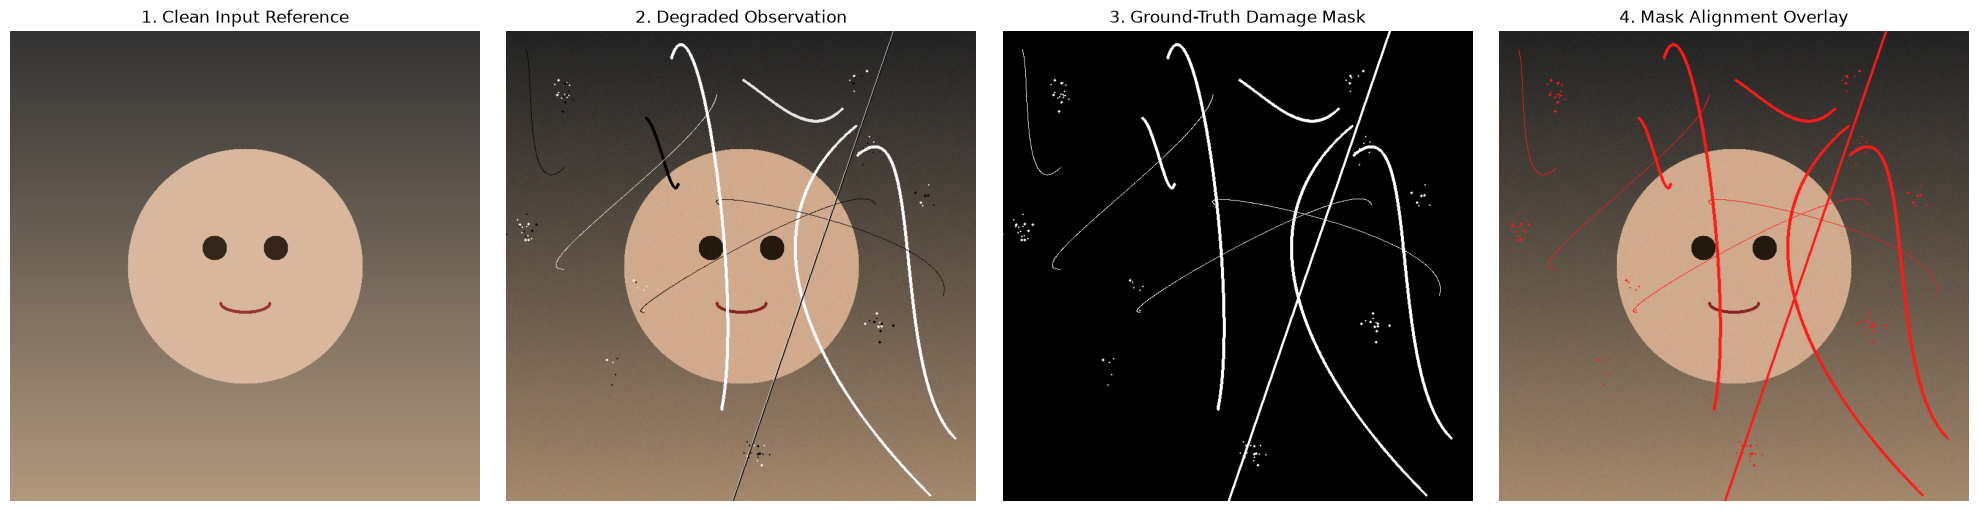

 [STAGE 1 PIPELINE READY]


In [11]:
# ==============================================================================
# Master Data Pipeline Orchestration & End-to-End Validation
# ==============================================================================

def run_master_data_pipeline(
    download_raw: bool = True,
    standardize_data: bool = True,
    generate_synthetic: bool = True,
    num_synthetic_train: int = 800,
    num_synthetic_val: int = 200,
    max_openphoto_pairs: int = 1000
):
    """
    Executes the end-to-end Stage 1 data ingestion, standardization, and verification pipeline.
    
    1. Ingestion: Verifies and streams raw datasets to data/raw/.
    2. Standardization: Normalizes images into clean sRGB PNGs and manifests in data/cleaned/.
    3. Synthetic Generation: Procedurally degrades clean base photographs into data/synthetic/.
    4. Tiling Fidelity: Validates Hann-window blending reconstruction precision (MSE & PSNR).
    5. DataLoader Verification: Confirms batch collation and tensor shape compliance.
    6. Visual Diagnostics: Displays 4-panel diagnostic comparison.
    """
    print("=" * 70)
    print(" [STAGE 1 MASTER DATA PIPELINE EXECUTION]")
    print("=" * 70)

    # 1. Download raw datasets into data/raw/
    raw_artefact_dir = RAW_DATA_DIR / "artefact"
    raw_openphoto_dir = RAW_DATA_DIR / "openphoto_restore"
    raw_film_dir = RAW_DATA_DIR / "film_scans_4k"
    raw_humanface_dir = RAW_DATA_DIR / "humanface8000"

    if download_raw:
        print("\n>>> STEP 1: Ingesting raw datasets into data/raw/...")
        try:
            download_artefact_dataset(raw_artefact_dir)
        except Exception as exc:
            print(f"[Notice] ARTeFACT download: {exc}")

        try:
            download_openphoto_dataset(raw_openphoto_dir)
        except Exception as exc:
            print(f"[Notice] OpenPhoto Restore download: {exc}")

        try:
            download_film_scans_dataset(raw_film_dir)
        except Exception as exc:
            print(f"[Notice] Film scans download: {exc}")

        try:
            download_humanface_dataset(raw_humanface_dir)
        except Exception as exc:
            print(f"[Notice] humanface8000 download: {exc}")

    # 2. Standardize raw datasets into data/cleaned/
    cleaned_artefact_imgs = CLEANED_DATA_DIR / "artefact" / "images"
    cleaned_artefact_masks = CLEANED_DATA_DIR / "artefact" / "masks"
    cleaned_openphoto_clean = CLEANED_DATA_DIR / "openphoto_restore" / "clean"
    cleaned_openphoto_damaged = CLEANED_DATA_DIR / "openphoto_restore" / "damaged"
    cleaned_humanface_color = CLEANED_DATA_DIR / "humanface8000" / "color"
    cleaned_humanface_gray = CLEANED_DATA_DIR / "humanface8000" / "gray"
    cleaned_film_damaged = CLEANED_DATA_DIR / "film_scans_4k" / "damaged"
    cleaned_film_restored = CLEANED_DATA_DIR / "film_scans_4k" / "restored"

    if standardize_data:
        print("\n>>> STEP 2: Standardizing images into data/cleaned/...")
        if raw_artefact_dir.exists():
            n_art = standardize_artefact_from_parquet(raw_artefact_dir, cleaned_artefact_imgs, cleaned_artefact_masks)
            print(f" - ARTeFACT pairs unpacked: {n_art}")

        if raw_openphoto_dir.exists():
            n_op = standardize_openphoto_from_parquet(
                raw_openphoto_dir,
                cleaned_openphoto_clean,
                cleaned_openphoto_damaged,
                max_pairs=max_openphoto_pairs
            )
            print(f" - OpenPhoto Restore pairs unpacked: {n_op}")

        if raw_humanface_dir.exists():
            n_hf = standardize_humanface_from_raw(raw_humanface_dir, cleaned_humanface_color, cleaned_humanface_gray, max_pairs=1000)
            print(f" - humanface8000 pairs unpacked: {n_hf}")

        if raw_film_dir.exists():
            n_film = standardize_film_scans_from_raw(raw_film_dir, cleaned_film_damaged, cleaned_film_restored)
            print(f" - Film Scans pairs unpacked: {n_film}")

    # 3. Generate deterministic synthetic dataset in data/synthetic/
    if generate_synthetic:
        print("\n>>> STEP 3: Generating synthetic dataset in data/synthetic/...")
        clean_sources = sorted(list(cleaned_openphoto_clean.glob("*.png")))
        if not clean_sources:
            clean_sources = sorted(list(cleaned_artefact_imgs.glob("*.png")))

        print(f" - Base clean images available: {len(clean_sources)}")
        if clean_sources:
            counts = generate_and_cache_synthetic_dataset(
                clean_images=clean_sources,
                output_root=SYNTHETIC_DATA_DIR,
                num_train=num_synthetic_train,
                num_val=num_synthetic_val,
                crop_size=256,
                seed=42
            )
            print(f" - Synthetic dataset generated: {counts}")

    # 4. Tiling verification test
    print("\n>>> STEP 4: Running tiling verification...")
    test_pattern = create_synthetic_test_image(size=768)
    gen = SyntheticDamageGenerator(severity="medium")
    deg_img, clean_ref, test_mask = gen(test_pattern)

    tile_mgr = TileManager(tile_size=512, overlap=64)
    tiles, meta = tile_mgr.split_into_tiles(deg_img)
    recon = tile_mgr.merge_tiles(tiles, meta)

    mse = float(np.mean((deg_img - recon) ** 2))
    psnr = 10.0 * np.log10(1.0 / (mse + 1e-10))
    print(f" - Synthetic Pattern Reconstruction MSE:  {mse:.2e}")
    print(f" - Synthetic Pattern Reconstruction PSNR: {psnr:.2f} dB")
    assert psnr > 40.0, "Tiling error exceeded tolerance."

    # Verify tiling reconstruction on real 3K archival film scan
    real_scans = sorted(list(cleaned_film_damaged.glob("*.png")))
    if real_scans:
        with Image.open(real_scans[0]) as r_img:
            r_arr = np.array(r_img, dtype=np.float32) / 255.0
        r_tiles, r_meta = tile_mgr.split_into_tiles(r_arr)
        r_recon = tile_mgr.merge_tiles(r_tiles, r_meta)
        r_mse = float(np.mean((r_arr - r_recon) ** 2))
        r_psnr = 10.0 * np.log10(1.0 / (r_mse + 1e-10))
        print(f" - Real Film Scan ({real_scans[0].name}, {r_arr.shape[1]}x{r_arr.shape[0]}) Reconstruction PSNR: {r_psnr:.2f} dB ({len(r_tiles)} tiles)")
        assert r_psnr > 40.0, "Real scan tiling error exceeded tolerance."
    print(" [SUCCESS] Tiling verified across synthetic and real archival film scans.")

    # 5. PyTorch Dataset loading test
    print("\n>>> STEP 5: Verifying PyTorch DataLoaders...")
    if (SYNTHETIC_DATA_DIR / "train" / "damaged").exists():
        ds = CachedSyntheticDataset(SYNTHETIC_DATA_DIR / "train")
        loader = DataLoader(ds, batch_size=4, shuffle=True)
        batch = next(iter(loader))
        print(f" - Batch shapes: dmg={tuple(batch['damaged'].shape)}, clean={tuple(batch['clean'].shape)}, mask={tuple(batch['mask'].shape)}")
        print(" [SUCCESS] PyTorch DataLoader verified.")

    # 6. Diagnostic Visual Plots
    render_pipeline_diagnostics(clean_ref, deg_img, test_mask)
    print("=" * 70)
    print(" [STAGE 1 PIPELINE READY]")
    print("=" * 70)


# Execute the master data pipeline
run_master_data_pipeline(
    download_raw=True,
    standardize_data=True,
    generate_synthetic=True,
    num_synthetic_train=800,
    num_synthetic_val=200,
    max_openphoto_pairs=1000
)


## 9. Next Steps and Stage Handoff

Stage 1 data ingestion, format standardization, and synthetic damage caching are complete. Downstream model training stages can directly ingest clean standardized tensors and masks from `data/cleaned/` and `data/synthetic/`:
- **Stage 2: Damage Detection** (`notebooks/02_damage_detection/02_damage_detection.ipynb`): Training U-Net and SegFormer backbones on paired binary damage masks for precision defect localization.
- **Stage 3: Inpainting and Physical Repair** (`notebooks/03_repair/03_repair.ipynb`): Training latent-space autoencoders and partial-convolution networks for defect erasure and surface reconstruction.
- **Stage 4: Colorization** (`notebooks/04_colorization/04_colorization.ipynb`): Training dual-path chrominance estimation models in CIE LAB color space.
- **Stage 5: Super-Resolution & Enhancement** (`notebooks/05_enhancement/05_enhancement.ipynb`): Deploying generative adversarial super-resolution networks for facial detail enhancement and archival film scan upscaling.
